# Why $\ell_1$ finds sparse solutions

Compressed sensing wants the sparsest coefficient vector $\boldsymbol{s}$
that is consistent with the data, that is $\min\|\boldsymbol{s}\|_0$, where
$\|\boldsymbol{s}\|_0$ counts the nonzero entries. That count is
combinatorial, so in practice we replace it by the closest *convex*
function, $\|\boldsymbol{s}\|_1=\sum_i|s_i|$. This notebook shows, in two
dimensions where everything can be drawn, why that particular replacement
keeps the sparsity while the more familiar squared norm $\|\cdot\|_2^2$
(ridge) does not.

**In this notebook you will**

* compare the $\ell_0$, $\ell_1$, $\ell_2$ and $\ell_\infty$ norms as
  landscapes and as unit balls;
* see where a least-squares loss first touches an $\ell_2$ ball and an
  $\ell_1$ ball, and why the $\ell_1$ contact lands on an axis;
* look at the penalised objective surfaces and the coefficient paths as the
  penalty weight $\lambda$ grows;
* count, over 500 random problems, how often each penalty returns an exactly
  sparse answer, and check the count against a formula.

**Before this notebook:** `cs_illustrations` (and `cs_sparsity`).
**Next:** `cs_phase_transition`.
**Runtime:** a few seconds.

### The toy problem

The toy problem is a two-parameter least-squares fit with a penalty. Here
$\boldsymbol{\theta}=(\theta_1,\theta_2)$ is the unknown, $\boldsymbol{a}=(a_1,a_2)$ is the
unpenalised optimum (the answer without any penalty), $\lambda\ge 0$ is the
penalty weight and $R$ is the penalty:

$$\min_{\boldsymbol{\theta}}\ \|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\,R(\boldsymbol{\theta}),
  \qquad R=\|\boldsymbol{\theta}\|_1\ \text{(lasso)}\quad\text{or}\quad
  R=\|\boldsymbol{\theta}\|_2^2\ \text{(ridge)},$$

whose minimizers are known in closed form:

$$\theta_i^{\ell_1}=\operatorname{sign}(a_i)\max(|a_i|-\lambda/2,\,0),\qquad
  \theta_i^{\ell_2}=\frac{a_i}{1+\lambda}.$$

The first is **soft-thresholding**: it moves every coordinate toward zero by
$\lambda/2$ and sets it exactly to zero if $|a_i|\le\lambda/2$. The second
only divides by $1+\lambda$, so it shrinks but never reaches zero. Because
the problem is separable (each $\theta_i$ appears in its own term), both formulas
act coordinate by coordinate.

The next cell loads NumPy, Matplotlib and the course plotting helpers
(`save_dual` writes a light and a dark version of every figure to
`../figures`).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))
import numpy as np
import matplotlib.pyplot as plt
from pyutils import set_plot_style, save_dual, fg, muted
set_plot_style()

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)

## Parameters (edit these)

Every setting of the notebook lives in this cell.

* `A` is the unpenalised optimum $\boldsymbol{a}=(2.0,\,1.3)$ of the toy
  problem.
* `LAM` is the penalty weight $\lambda=3$ used for the minimizers, the
  surfaces and the random experiment.
* `LAM_MAX` is the largest $\lambda$ on the coefficient-path plot.
* `N_DRAWS` and `DRAW_STD` set the random experiment in Section 5: 500
  optima drawn as $\boldsymbol{a}\sim\mathcal{N}(\boldsymbol{0},\,2^2\mathbf{I})$,
  where $\mathbf{I}$ is the $2\times 2$ identity matrix.
* `WLIM` is the half-width of the plotting window for $\boldsymbol{\theta}$.
* `SEED` fixes the random number generator, so the run is reproducible.

In [2]:
SEED = 0
A = np.array([2.0, 1.3])        # unregularised optimum of the separable toy problem
LAM = 3.0                       # penalty weight for the surface / valley pictures
LAM_MAX = 8.0                   # range of the coefficient paths
N_DRAWS = 500                   # random problems in the axis-hit experiment
DRAW_STD = 2.0                  # spread of the random optima a ~ N(0, DRAW_STD^2 I)
WLIM = 2.5                      # plotting window for w

rng = np.random.default_rng(SEED)

### The closed-form minimizers, and a brute-force check

`soft_threshold(z, t)` applies $\operatorname{sign}(z)\max(|z|-t,0)$
entrywise. `minimizers(a, lam)` returns the lasso minimizer (soft-threshold
at $t=\lambda/2$) and the ridge minimizer $\boldsymbol{a}/(1+\lambda)$.
We evaluate both at $\boldsymbol{a}=(2.0,1.3)$ and $\lambda=3$.

To make sure the formulas are right, we also evaluate both objectives
$J_1=\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_1$ and
$J_2=\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_2^2$ on a
fine $1001\times1001$ grid and check that the grid minimum agrees with the
formula to within the grid spacing.

In [3]:
def soft_threshold(z, t):
    # shrink |z| by t; anything that would cross zero is set exactly to zero
    return np.sign(z) * np.maximum(np.abs(z) - t, 0.0)


def minimizers(a, lam):
    """Closed-form lasso and ridge minimizers of ||w - a||^2 + lam R(w)."""
    return soft_threshold(a, lam / 2.0), a / (1.0 + lam)


w_l1, w_l2 = minimizers(A, LAM)
print(f"lambda={LAM}: lasso w = {w_l1},  ridge w = {w_l2}")
assert w_l1[1] == 0.0 and w_l1[0] > 0, "lasso must zero the smaller coordinate exactly"
assert np.all(w_l2 != 0), "ridge only shrinks"

# brute-force check of the closed forms on a fine grid
g = np.linspace(-WLIM, WLIM, 1001); W1, W2 = np.meshgrid(g, g)
loss = (W1 - A[0])**2 + (W2 - A[1])**2
J1 = loss + LAM * (np.abs(W1) + np.abs(W2))
J2 = loss + LAM * (W1**2 + W2**2)
i1 = np.unravel_index(np.argmin(J1), J1.shape); i2 = np.unravel_index(np.argmin(J2), J2.shape)
assert np.allclose([W1[i1], W2[i1]], w_l1, atol=1e-2)
assert np.allclose([W1[i2], W2[i2]], w_l2, atol=1e-2)

lambda=3.0: lasso w = [0.5 0. ],  ridge w = [0.5   0.325]


At $\lambda=3$ the lasso returns $\boldsymbol{\theta}=(0.5,\,0)$: the smaller
coordinate $a_2=1.3$ is below the threshold $\lambda/2$, so it is set
exactly to zero. Ridge returns $(0.5,\,0.325)$: both coordinates are shrunk
by the same factor, and neither is zero. The grid search agrees with both
formulas (the asserts pass).

## 1. The norms as landscapes

We draw four functions of $\boldsymbol{\theta}=(\theta_1,\theta_2)$ on the square
$[-1.5,1.5]^2$:
$\|\boldsymbol{\theta}\|_0$ (number of nonzeros),
$\|\boldsymbol{\theta}\|_1=|\theta_1|+|\theta_2|$,
$\|\boldsymbol{\theta}\|_2=\sqrt{\theta_1^2+\theta_2^2}$ and
$\|\boldsymbol{\theta}\|_\infty=\max(|\theta_1|,|\theta_2|)$.
On top of each we draw its unit ball, the set where the norm equals 1.
The unit balls are traced with the polar angle $\theta$: each direction
$(\cos\theta,\sin\theta)$ is divided by its own norm, which places it on the
ball. $\ell_0$ has no unit ball worth drawing, so that panel has none.

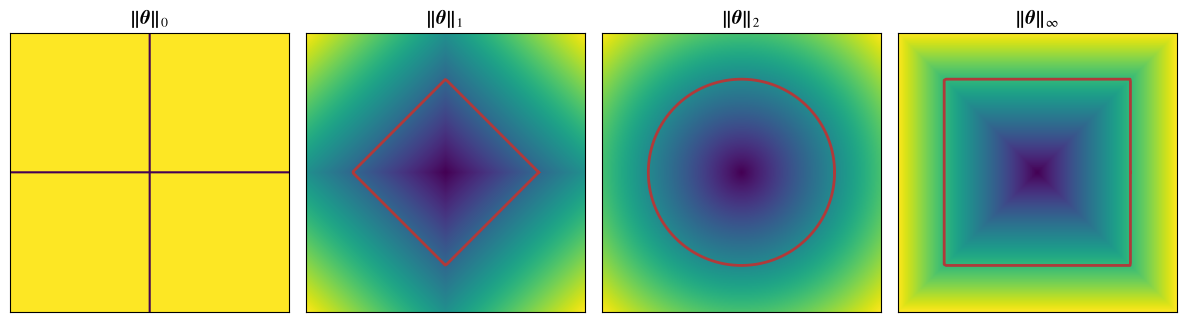

In [4]:
def plot_norm_balls():
    gg = np.linspace(-1.5, 1.5, 401); X1, X2 = np.meshgrid(gg, gg)
    norms = [((X1 != 0).astype(float) + (X2 != 0)), np.abs(X1) + np.abs(X2),
             np.hypot(X1, X2), np.maximum(np.abs(X1), np.abs(X2))]
    # l0 on a grid is 2 almost everywhere; mark the axes explicitly
    norms[0] = np.where((np.abs(X1) < 0.012) | (np.abs(X2) < 0.012), 1.0, 2.0)
    titles = [r'$\|\boldsymbol{\theta}\|_0$', r'$\|\boldsymbol{\theta}\|_1$',
              r'$\|\boldsymbol{\theta}\|_2$', r'$\|\boldsymbol{\theta}\|_\infty$']
    th = np.linspace(0, 2*np.pi, 400)
    balls = [None, (np.cos(th) / (np.abs(np.cos(th)) + np.abs(np.sin(th))),
                    np.sin(th) / (np.abs(np.cos(th)) + np.abs(np.sin(th)))),
             (np.cos(th), np.sin(th)),
             (np.cos(th) / np.maximum(np.abs(np.cos(th)), np.abs(np.sin(th))),
              np.sin(th) / np.maximum(np.abs(np.cos(th)), np.abs(np.sin(th))))]
    fig, ax = plt.subplots(1, 4, figsize=(12, 3.3))
    for a, Z, ttl, b in zip(ax, norms, titles, balls):
        a.imshow(Z, extent=[-1.5, 1.5, -1.5, 1.5], origin='lower', cmap='viridis')
        if b is not None:
            a.plot(*b, color='C3', lw=2)
        a.set_title(ttl, fontsize=14); a.set_xticks([]); a.set_yticks([]); a.grid(False)
    plt.tight_layout()


save_dual(plot_norm_balls, 'cs_norm_balls', FIG)
plt.show()

**How to read this figure.** Four panels, one per norm, all on the same
square $-1.5\le \theta_1,\theta_2\le 1.5$ (horizontal axis $\theta_1$, vertical axis $\theta_2$;
ticks are hidden). Colour shows the value of the norm: dark purple is small,
yellow is large. The red curve is the unit ball (norm equal to 1).

**What it shows.**
* $\|\boldsymbol{\theta}\|_0$ is yellow (value 2) almost everywhere, and dark
  (value 1) only on the two axes. It is flat, so there is no slope to follow
  toward a sparse answer. This is why it cannot be minimised directly.
* $\|\boldsymbol{\theta}\|_1$ has a diamond as unit ball, with **corners on the
  axes**. Corners are exactly the sparse points (one coordinate zero). It is
  the smallest convex function that keeps this property.
* $\|\boldsymbol{\theta}\|_2$ has a round unit ball. No point of the circle is
  special, so it has no preference for the axes.
* $\|\boldsymbol{\theta}\|_\infty$ has a square unit ball with corners on the
  diagonals. It favours *equal* magnitudes, the opposite of sparsity.

## 2. Constrained picture: where the loss first touches the ball

The penalised problem is equivalent to minimising the loss inside a norm
ball $R(\boldsymbol{\theta})\le\tau$ for some radius $\tau$. To make the picture
realistic we use a small regression with correlated features:

* $\mathbf{X}$ is a $60\times 2$ data matrix (`Xd`) whose two columns are
  correlated;
* $\boldsymbol{\theta}_{\text{true}}=(2.2,\,0.6)$ is the true coefficient vector;
* $\boldsymbol{y}=\mathbf{X}\boldsymbol{\theta}_{\text{true}}+\text{noise}$ is
  the data vector (`yd`), with noise standard deviation 0.2;
* the loss is $\|\boldsymbol{y}-\mathbf{X}\boldsymbol{\theta}\|_2^2$, minimised
  without constraint at the ordinary-least-squares (OLS) point
  $\boldsymbol{\theta}_{\text{OLS}}$;
* the ball radius is $\tau=1.2$ (`TAU`).

The loss contours are tilted ellipses around the OLS point. Grow the
ellipses until they first touch the ball. That contact point is the
constrained minimizer. We find it by tracing the boundary of the circle
($\ell_2$ ball) and of the diamond ($\ell_1$ ball) with 20001 points each,
and picking the boundary point with the smallest loss. This works because the
OLS point lies outside both balls, so the constrained minimum is on the
boundary.

In [5]:
nobs = 60
Xd = rng.standard_normal((nobs, 2)) @ np.array([[1.0, 0.0], [0.6, 0.5]])
w_true = np.array([2.2, 0.6])
yd = Xd @ w_true + 0.2 * rng.standard_normal(nobs)
w_ols = np.linalg.lstsq(Xd, yd, rcond=None)[0]
TAU = 1.2


def ls_loss(w):
    # w has shape (2, n_points): evaluates the loss at many points at once
    r = yd[:, None] - Xd @ w
    return np.sum(r**2, axis=0)


th = np.linspace(0, 2*np.pi, 20001)
circ = TAU * np.vstack([np.cos(th), np.sin(th)])
diam = TAU * np.vstack([np.cos(th), np.sin(th)]) / (np.abs(np.cos(th)) + np.abs(np.sin(th)))
# contact point = boundary point with the lowest loss
w_ridge_c = circ[:, np.argmin(ls_loss(circ))]
w_lasso_c = diam[:, np.argmin(ls_loss(diam))]
print(f"OLS {w_ols}; ridge-ball contact {w_ridge_c}; lasso-ball contact {w_lasso_c}")
assert ls_loss(w_ols[:, None])[0] < ls_loss(w_lasso_c[:, None])[0], "OLS must lie outside the ball"
assert abs(w_lasso_c[1]) < 1e-3 * TAU, "the diamond must be touched at its corner on the w1 axis"
assert np.min(np.abs(w_ridge_c)) > 0.1, "the circle must be touched off-axis"

OLS [2.19972137 0.51126524]; ridge-ball contact [1.15796486 0.31482912]; lasso-ball contact [1.2 0. ]


The OLS point is about $(2.20,\,0.51)$, outside both balls. The circle is
touched at about $(1.16,\,0.31)$, where both coefficients are nonzero. The
diamond is touched at $(1.2,\,0)$, its corner on the $\theta_1$ axis, so the
second coefficient is exactly zero.

The next cell draws this. Grey curves are loss contours, the blue curve is
the contour that just touches the ball.

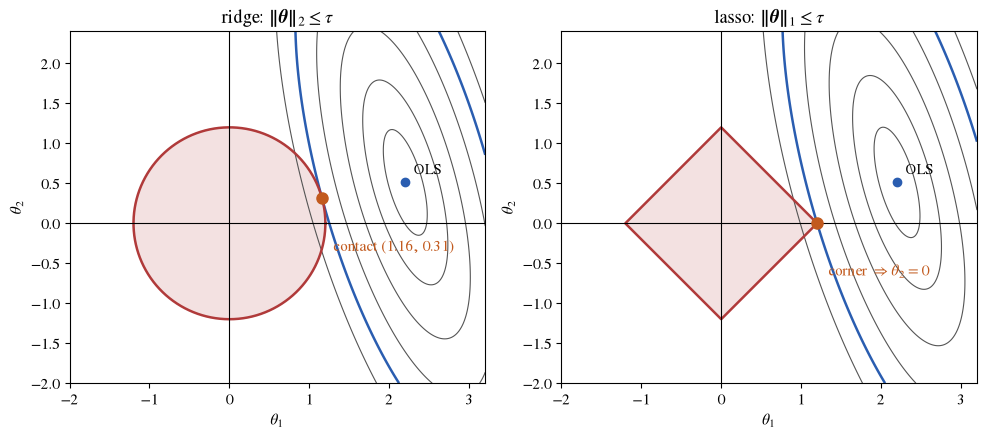

In [6]:

def plot_ball_contact():
    gg = np.linspace(-2.0, 3.2, 300); G1, G2 = np.meshgrid(gg, gg)
    L = ls_loss(np.vstack([G1.ravel(), G2.ravel()])).reshape(G1.shape)
    fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
    for a, ball, wc, name in [(ax[0], circ, w_ridge_c, r'ridge: $\|\boldsymbol{\theta}\|_2\leq\tau$'),
                              (ax[1], diam, w_lasso_c, r'lasso: $\|\boldsymbol{\theta}\|_1\leq\tau$')]:
        lev = ls_loss(wc[:, None])[0]
        lmin = ls_loss(w_ols[:, None])[0]
        a.contour(G1, G2, L, levels=lmin + (lev - lmin) * np.array([0.04, 0.15, 0.35, 0.65, 1.4]),
                  colors=[muted()], linewidths=0.8)
        a.contour(G1, G2, L, levels=[lev], colors=['C0'], linewidths=1.8)
        a.fill(ball[0], ball[1], color='C3', alpha=0.15); a.plot(ball[0], ball[1], color='C3', lw=1.8)
        a.plot(*w_ols, 'o', color='C0'); a.annotate('OLS', w_ols, xytext=(6, 6), textcoords='offset points')
        a.plot(*wc, 'o', color='C1', ms=8, zorder=5)
        a.axhline(0, color=fg(), lw=0.8); a.axvline(0, color=fg(), lw=0.8)
        a.set(xlabel=r'$\theta_1$', ylabel=r'$\theta_2$', title=name, aspect='equal',
              xlim=(-2.0, 3.2), ylim=(-2.0, 2.4))
        a.grid(False)
    ax[0].annotate(f'contact ({w_ridge_c[0]:.2f}, {w_ridge_c[1]:.2f})', w_ridge_c,
                   xytext=(8, -38), textcoords='offset points', color='C1')
    ax[1].annotate(r'corner $\Rightarrow \theta_2=0$', w_lasso_c,
                   xytext=(8, -38), textcoords='offset points', color='C1')
    plt.tight_layout()


save_dual(plot_ball_contact, 'cs_l1l2_contact', FIG)
plt.show()

**How to read this figure.** Two panels in the $(\theta_1,\theta_2)$ plane: ridge
(left, the $\ell_2$ ball is a circle) and lasso (right, the $\ell_1$ ball is
a diamond). Both balls have radius $\tau=1.2$ and are shaded red. The blue
dot marks the OLS point. Thin grey curves are contours of the loss, which
grows as you move away from OLS. The thick blue curve is the lowest contour
that reaches the ball. The orange dot is where it touches: the constrained
minimizer.

**What it shows.** The two problems use the *same* loss and the *same*
radius; only the shape of the ball differs. The tilted ellipse touches the
circle on its smooth side, at about $(1.16,\,0.31)$, so ridge keeps both
coefficients. It touches the diamond at its corner $(1.2,\,0)$, so the lasso
sets $\theta_2$ exactly to zero. Corners stick out toward the loss contours, so
a growing ellipse is likely to meet a corner first. A circle has no corners,
so its contact point is almost never on an axis.

## 3. Penalised picture: the objective surfaces

Now we return to the separable toy problem with
$\boldsymbol{a}=(2,\,1.3)$ and $\lambda=3$, and plot the full penalised
objectives as 3-D surfaces over a $120\times120$ grid of
$\boldsymbol{\theta}$:
lasso $\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_1$
and ridge $\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_2^2$.
The red dot is the closed-form minimizer from the start of the notebook,
placed at its objective value `zmin`.

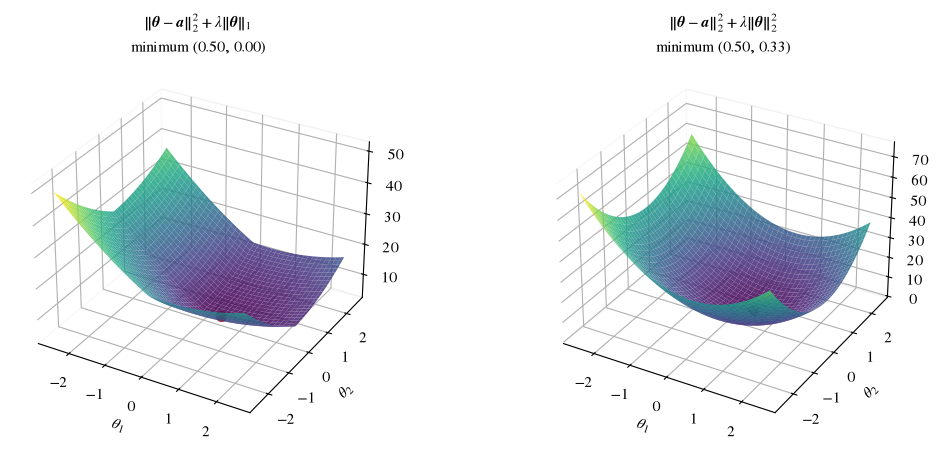

In [7]:
def plot_surfaces():
    gg = np.linspace(-WLIM, WLIM, 120); G1, G2 = np.meshgrid(gg, gg)
    Ls = (G1 - A[0])**2 + (G2 - A[1])**2
    fig = plt.figure(figsize=(11, 4.6))
    for j, (Z, w, ttl) in enumerate([
            (Ls + LAM * (np.abs(G1) + np.abs(G2)), w_l1,
             r'$\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_1$'),
            (Ls + LAM * (G1**2 + G2**2), w_l2,
             r'$\|\boldsymbol{\theta}-\boldsymbol{a}\|_2^2+\lambda\|\boldsymbol{\theta}\|_2^2$')]):
        a = fig.add_subplot(1, 2, j + 1, projection='3d')
        a.plot_surface(G1, G2, Z, cmap='viridis', rstride=3, cstride=3, linewidth=0, alpha=0.85)
        zmin = (w[0]-A[0])**2 + (w[1]-A[1])**2 + LAM*(np.abs(w).sum() if j == 0 else (w**2).sum())
        a.scatter([w[0]], [w[1]], [zmin], color='C3', s=50, depthshade=False)
        a.set_title(ttl + f'\nminimum ({w[0]:.2f}, {w[1]:.2f})', fontsize=11)
        a.set_xlabel(r'$\theta_1$'); a.set_ylabel(r'$\theta_2$'); a.view_init(30, -60)
        a.xaxis.pane.fill = a.yaxis.pane.fill = a.zaxis.pane.fill = False
    plt.tight_layout()


save_dual(plot_surfaces, 'cs_l1l2_surfaces', FIG)
plt.show()

**How to read this figure.** Left: the lasso objective. Right: the ridge
objective. The horizontal axes are $\theta_1$ and $\theta_2$, from $-2.5$ to $2.5$;
the vertical axis and the colour (purple low, yellow high) show the
objective value. The panel title gives the minimizer, which is also marked
by the red dot (it can be partly hidden by the surface).

**What it shows.** The lasso surface is not smooth: the $|\theta_1|$ and $|\theta_2|$
terms put a **crease** (a kink) along each axis. Its minimum, at
$(0.50,\,0.00)$, sits *in* the crease along $\theta_2=0$. A kink can hold the
minimum there even though the data pull $\theta_2$ toward $a_2=1.3$. The ridge
surface is a smooth bowl. Its minimum, at $(0.50,\,0.33)$, is just pulled
toward the origin, and a smooth bowl has no reason to put it on an axis.

## 4. Coefficient paths

We now vary the penalty weight $\lambda$ from 0 to `LAM_MAX` $=8$ (400
values) and record both minimizers at each value. These curves are called
coefficient paths. From the closed forms we expect:

* lasso coefficients fall **linearly**, $|\theta_i|=|a_i|-\lambda/2$, and reach
  zero at the finite value $\lambda=2|a_i|$ (the smaller one first);
* ridge coefficients decay like $a_i/(1+\lambda)$ and never reach zero.

The asserts check that $\theta_2$ of the lasso vanishes at $\lambda=2|a_2|$ (to
within the $\lambda$ grid spacing) and that the ridge coefficients stay
positive.

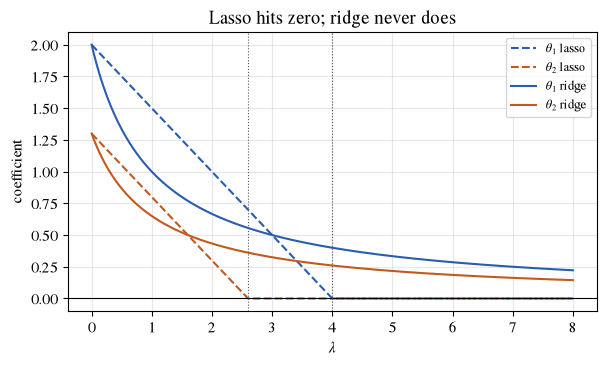

In [8]:
lams = np.linspace(0, LAM_MAX, 400)
paths_l1 = np.array([minimizers(A, l)[0] for l in lams])
paths_l2 = np.array([minimizers(A, l)[1] for l in lams])
lam_zero = lams[np.argmax(paths_l1[:, 1] == 0)]    # first lambda where lasso w2 is exactly 0
assert abs(lam_zero - 2 * A[1]) < 0.05, "w2 must vanish at lambda = 2|a2|"
assert np.all(paths_l2 > 0)


def plot_paths():
    fig, ax = plt.subplots(figsize=(6.2, 3.8))
    ax.plot(lams, paths_l1[:, 0], color='C0', ls='--', label=r'$\theta_1$ lasso')
    ax.plot(lams, paths_l1[:, 1], color='C1', ls='--', label=r'$\theta_2$ lasso')
    ax.plot(lams, paths_l2[:, 0], color='C0', label=r'$\theta_1$ ridge')
    ax.plot(lams, paths_l2[:, 1], color='C1', label=r'$\theta_2$ ridge')
    ax.axhline(0, color=fg(), lw=0.8)
    for ai in A:
        ax.axvline(2 * ai, color=muted(), lw=0.8, ls=':')
    ax.set(xlabel=r'$\lambda$', ylabel='coefficient', title='Lasso hits zero; ridge never does')
    ax.legend(fontsize=9); plt.tight_layout()


save_dual(plot_paths, 'cs_l1l2_paths', FIG)
plt.show()

**How to read this figure.** The horizontal axis is the penalty weight
$\lambda$; the vertical axis is the coefficient value. Blue is $\theta_1$, orange
is $\theta_2$. Dashed lines are the lasso, solid lines are ridge. The two dotted
vertical lines mark $\lambda=2a_2=2.6$ and $\lambda=2a_1=4$, where the lasso
predicts each coefficient to vanish. The black horizontal line is zero.

**What it shows.** At $\lambda=0$ both methods start from
$\boldsymbol{a}=(2,\,1.3)$. The lasso lines are straight and hit zero
exactly at the dotted lines: $\theta_2$ first at $\lambda=2.6$, then $\theta_1$ at
$\lambda=4$. For $2.6<\lambda<4$ the lasso answer has exactly one nonzero,
which is a sparse model. The ridge curves bend down smoothly and are still
positive at $\lambda=8$: ridge makes coefficients small but never zero. So
$\lambda$ in the lasso acts as a sparsity knob; in ridge it does not.

## 5. How often is the answer exactly sparse?

One example could be luck. So we draw 500 random optima
$\boldsymbol{a}\sim\mathcal{N}(\boldsymbol{0},\,2^2\mathbf{I})$ (each
coordinate is Gaussian with standard deviation 2) and solve both problems
at $\lambda=3$ with the closed forms. We count the minimizers that land **on
an axis**, meaning at least one coefficient is exactly zero.

There is also a prediction. The lasso zeroes coordinate $i$ when
$|a_i|\le\lambda/2$. For one Gaussian coordinate this has probability
$p_0=2\Phi_{\mathcal{N}}\!\big(\lambda/(2\sigma)\big)-1$, where
$\Phi_{\mathcal{N}}$ is the standard normal cumulative distribution function
and $\sigma=2$. The two coordinates are independent, so the chance that at
least one is zeroed is $1-(1-p_0)^2$.

In [9]:
As = DRAW_STD * rng.standard_normal((N_DRAWS, 2))
M1 = soft_threshold(As, LAM / 2)
M2 = As / (1 + LAM)
hit1 = np.mean(np.any(M1 == 0, axis=1)); hit2 = np.mean(np.any(M2 == 0, axis=1))
from scipy.stats import norm as _norm
p0 = 2 * _norm.cdf(LAM / 2 / DRAW_STD) - 1        # P(|a_i| <= lam/2)
hit_theory = 1 - (1 - p0)**2                      # P(at least one coordinate is zeroed)
print(f"axis hits: lasso {hit1:.3f} (theory {hit_theory:.3f}), ridge {hit2:.3f}")
assert hit2 == 0.0
assert abs(hit1 - hit_theory) < 0.05, "empirical lasso hit rate must match 1-(1-p0)^2"

axis hits: lasso 0.808 (theory 0.795), ridge 0.000


The lasso lands on an axis in 0.808 of the 500 draws (about 81%), close to
the prediction 0.795; the asserts allow a difference of up to 0.05 for
sampling noise. Ridge lands on an axis in 0.000 of the draws: dividing by
$1+\lambda$ never produces an exact zero.

The next cell plots the 500 optima and the corresponding minimizers.

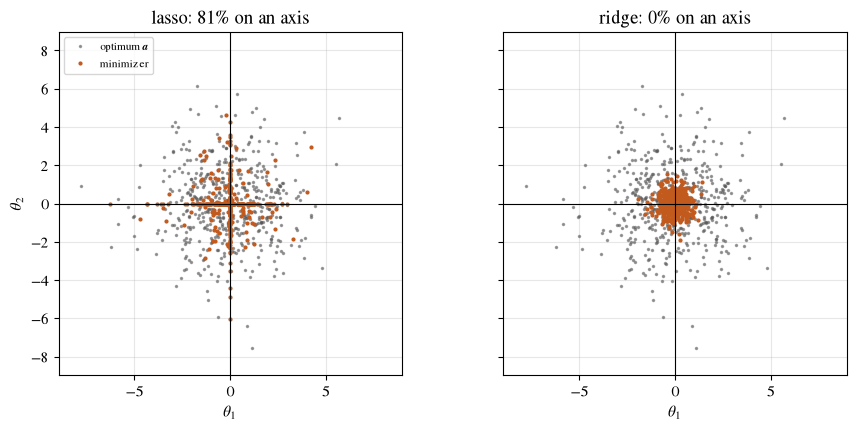

In [10]:
def plot_axis_hits():
    fig, ax = plt.subplots(1, 2, figsize=(9.5, 4.4), sharex=True, sharey=True)
    lim = 1.15 * np.max(np.abs(As))
    for a, M, ttl in [(ax[0], M1, f'lasso: {100*hit1:.0f}% on an axis'),
                      (ax[1], M2, f'ridge: {100*hit2:.0f}% on an axis')]:
        a.plot(As[:, 0], As[:, 1], '.', color=muted(), ms=3, alpha=0.5, label=r'optimum $\boldsymbol{a}$')
        a.plot(M[:, 0], M[:, 1], '.', color='C1', ms=4, label='minimizer')
        a.axhline(0, color=fg(), lw=0.8); a.axvline(0, color=fg(), lw=0.8)
        a.set(title=ttl, xlabel=r'$\theta_1$', aspect='equal', xlim=(-lim, lim), ylim=(-lim, lim))
    ax[0].set_ylabel(r'$\theta_2$'); ax[0].legend(fontsize=8, loc='upper left')
    plt.tight_layout()


save_dual(plot_axis_hits, 'cs_l1l2_axis_hits', FIG)
plt.show()

**How to read this figure.** Two panels in the $(\theta_1,\theta_2)$ plane with the
same axes: lasso (left) and ridge (right). Grey dots are the 500 random
optima $\boldsymbol{a}$ (identical in both panels). Orange dots are the
minimizers at $\lambda=3$. The black lines are the axes $\theta_1=0$ and $\theta_2=0$.
The panel title gives the share of minimizers that lie exactly on an axis.

**What it shows.** In the lasso panel the orange dots collapse onto the two
axes (81% of them, 0.808 in the printout). Every optimum within $\lambda/2$
of an axis is snapped onto it, and those near the origin are snapped to the
origin itself. The remaining orange dots are moved diagonally toward the
origin. In the ridge panel the orange dots form a shrunken copy of the grey
cloud, scaled by $1/(1+\lambda)$, and 0% of them lie on an axis. Exact
sparsity is the normal outcome for the lasso and essentially impossible for
ridge.

## Summary

* $\ell_1$ is the tightest convex stand-in for $\ell_0$, and its ball has
  corners exactly where vectors are sparse.
* Penalised or constrained, the geometry is the same: loss contours meet the
  diamond at a corner with positive probability, the circle almost never.
  In the constrained example the diamond was touched at $(1.2,\,0)$, the
  circle at about $(1.16,\,0.31)$.
* Algebraically the corner is soft-thresholding. At $\lambda=3$ it turned
  $\boldsymbol{a}=(2,\,1.3)$ into $(0.5,\,0)$, while ridge gave
  $(0.5,\,0.325)$. Over 500 random problems the lasso answer was exactly
  sparse 81% of the time (prediction 0.795), ridge 0%.
* Soft-thresholding is the step that every $\ell_1$ solver in
  `cs_recovery_fista` and `cs_portrait_fista` repeats.

## Try this

All settings are in the "Parameters (edit these)" cell. The asserts are
written for the default values, so keep the changes within the ranges
suggested here.

1. **A larger penalty.** Set `LAM = 3.8`. The lasso still zeroes $\theta_2$ (the
   threshold $\lambda/2=1.9$ exceeds $a_2=1.3$) and $\theta_1$ drops to almost
   zero. In Section 5 the share of lasso minimizers on an axis rises, and the
   prediction rises with it. Ridge stays at 0%.
2. **Wider random optima.** Set `DRAW_STD = 4.0`. Fewer optima fall within
   $\lambda/2$ of an axis, so the lasso hit rate in Section 5 drops, still in
   line with $1-(1-p_0)^2$. The grey cloud in the last figure spreads out.
3. **A smaller second coefficient.** Set `A = np.array([2.0, 0.5])`. In the
   coefficient-path figure the dashed orange line now reaches zero at
   $\lambda=2a_2=1.0$, much earlier than $\theta_1$. The lasso surface minimum
   still sits in the crease at $\theta_2=0$.
4. **A different random draw.** Change `SEED` and rerun. The regression
   data in Section 2 and the 500 random optima change, so the OLS point and
   the lasso hit rate move slightly. The prediction does not depend on the
   seed, and the qualitative picture does not change: the diamond is still
   touched at a corner, the circle off the axes.